# Lab01 · Доп. КТиД — гейзер Old Faithful

Дополнительное задание КТиД: **отдельный датасет и две случайные величины по нему**.
Нужно доказать, что величины случайны, проверить их зависимость (они относятся к одному событию)
и провести EDA.

Этот ноутбук — копия раздела 7 сайта-отчёта (вкладка «Доп. КТиД») в формате Jupyter.
Код самодостаточный: нужен только файл `public/geyser.csv` рядом с ноутбуком
(в Colab данные загрузятся из репозитория seaborn-data автоматически).

**Содержание**
1. [Общее описание данных](#data)
2. [Random Variable 01 — длительность извержения X](#rv1)
3. [Random Variable 02 — время ожидания Y](#rv2)
4. [Независимость X и Y](#indep)
5. [Ограничения: соседние извержения](#limits)
6. [Lab resume и cat_mark_table](#resume)
7. [Литература](#refs)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Единый стиль графиков (совпадает с сайтом-отчётом)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#E9E4D8", "grid.linewidth": 0.8,
    "axes.edgecolor": "#C9C4B8", "xtick.color": "#6B6F6A", "ytick.color": "#6B6F6A",
    "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.precision", 4)

### Вспомогательные функции
Те же функции, что в `geyser_study.py` проекта: статистики, смесь двух нормальных (ЕМ-алгоритм), зависимость и графики.

In [2]:
GEY_VARS = {
    'duration': ('Длительность извержения', 'мин'),
    'waiting': ('Время ожидания следующего извержения', 'мин'),
}


GEY_COLORS = {
    'data': '#1F6F78', 'soft': '#BFDCDC', 'short': '#3E8FB0', 'long': '#C8742B',
    'ref': '#A3333D', 'ink': '#1E2226', 'mix': '#C2408A',
}


def gey_check(frame):
    """Проверка схемы и значений: без этого выводы раздела теряют смысл."""
    for col in GEY_VARS:
        if col not in frame.columns:
            raise ValueError(f'В geyser.csv нет столбца {col}')
        if frame[col].isna().any():
            raise ValueError(f'В столбце {col} есть пропуски')
        if (frame[col] <= 0).any():
            raise ValueError(f'В столбце {col} есть неположительные значения')
    return frame


def gey_describe(x):
    x = pd.Series(np.asarray(x, dtype=float))
    q1, q3 = x.quantile([.25, .75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    w, p = stats.shapiro(x)
    return {
        'n': len(x), 'Среднее': x.mean(), 'Медиана': x.median(), 'Std': x.std(ddof=1),
        'Min': x.min(), 'Q1': q1, 'Q3': q3, 'Max': x.max(),
        'Асимметрия': x.skew(), 'Эксцесс': x.kurt(),
        'Уникальных значений': x.nunique(),
        'Граница IQR, нижняя': lo, 'Граница IQR, верхняя': hi,
        'Выбросов IQR': int(((x < lo) | (x > hi)).sum()),
        'Шапиро W': w, 'Шапиро p': p,
    }


def gey_mixture(x, iters=500, tol=1e-10):
    """Смесь двух нормальных распределений, ЕМ-алгоритм (Dempster, Laird, Rubin, 1977)."""
    x = np.asarray(x, dtype=float)
    split = np.median(x)
    lo, hi = x[x <= split], x[x > split]
    w, mu, sd = np.array([.5, .5]), np.array([lo.mean(), hi.mean()]), np.array([lo.std(), hi.std()])
    ll_old = -np.inf
    for _ in range(iters):
        dens = w * stats.norm.pdf(x[:, None], mu, sd)          # E-шаг
        total = dens.sum(axis=1)
        resp = dens / total[:, None]
        nk = resp.sum(axis=0)                                   # М-шаг
        w = nk / len(x)
        mu = (resp * x[:, None]).sum(axis=0) / nk
        sd = np.sqrt((resp * (x[:, None] - mu) ** 2).sum(axis=0) / nk)
        ll = np.log(total).sum()
        if ll - ll_old < tol:
            break
        ll_old = ll
    order = np.argsort(mu)
    w, mu, sd = w[order], mu[order], sd[order]
    ll = np.log((w * stats.norm.pdf(x[:, None], mu, sd)).sum(axis=1)).sum()
    return {'w': w, 'mu': mu, 'sd': sd, 'll': ll, 'k': 5, 'aic': 2 * 5 - 2 * ll}


def gey_mixture_cdf(t, m):
    return (m['w'] * stats.norm.cdf(np.asarray(t, dtype=float)[..., None], m['mu'], m['sd'])).sum(axis=-1)


def gey_mixture_pdf(t, m):
    return (m['w'] * stats.norm.pdf(np.asarray(t, dtype=float)[..., None], m['mu'], m['sd'])).sum(axis=-1)


def gey_fit_table(x):
    """Одна нормальная против смеси двух нормальных: AIC и расстояние KS."""
    x = np.asarray(x, dtype=float)
    mu, sd = stats.norm.fit(x)
    ll_n = stats.norm.logpdf(x, mu, sd).sum()
    m = gey_mixture(x)
    rows = [
        ['Нормальное', 2, 2 * 2 - 2 * ll_n, stats.kstest(x, stats.norm(mu, sd).cdf).statistic,
         f'μ = {mu:.3f}, σ = {sd:.3f}'],
        ['Смесь двух нормальных', 5, m['aic'], stats.kstest(x, lambda t: gey_mixture_cdf(t, m)).statistic,
         f'w = {m["w"][0]:.2f} / {m["w"][1]:.2f}; μ = {m["mu"][0]:.2f} / {m["mu"][1]:.2f}; '
         f'σ = {m["sd"][0]:.2f} / {m["sd"][1]:.2f}'],
    ]
    table = pd.DataFrame(rows, columns=['Модель', 'k', 'AIC', 'KS D', 'Параметры']).set_index('Модель')
    return table, m


def gey_dependence(frame):
    x, y = frame['duration'], frame['waiting']
    r, pr = stats.pearsonr(x, y)
    rho, ps = stats.spearmanr(x, y)
    table = pd.crosstab(pd.qcut(x, 4), pd.qcut(y, 4))
    chi2, pc, dof, expected = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    table.index = [f'{iv.left:.2f}–{iv.right:.2f} мин' for iv in table.index]
    table.index.name = 'длительность \\ ожидание'
    table.columns = [f'{iv.left:.0f}–{iv.right:.0f} мин' for iv in table.columns]
    return {'r': r, 'pr': pr, 'rho': rho, 'ps': ps, 'chi2': chi2, 'pc': pc, 'dof': dof,
            'v': v, 'min_expected': expected.min(), 'table': table}


def gey_regimes(frame, threshold):
    """Связь внутри режимов: короткие (< порога) и длинные (≥ порога) извержения."""
    rows = []
    for name, part in [('Короткие', frame[frame['duration'] < threshold]),
                       ('Длинные', frame[frame['duration'] >= threshold]),
                       ('Все', frame)]:
        if len(part) >= 3:
            r = stats.pearsonr(part['duration'], part['waiting'])[0]
            rho = stats.spearmanr(part['duration'], part['waiting'])[0]
        else:
            r = rho = np.nan
        rows.append([name, len(part), part['duration'].mean(), part['waiting'].mean(), r, rho])
    return pd.DataFrame(rows, columns=['Режим', 'n', 'Среднее X, мин', 'Среднее Y, мин',
                                       'Пирсон r', 'Спирмен ρ']).set_index('Режим')


def gey_lag(frame):
    """Соседние извержения: насколько наблюдения зависят друг от друга."""
    d, w = frame['duration'].to_numpy(), frame['waiting'].to_numpy()
    return {
        'X(i), X(i+1)': np.corrcoef(d[:-1], d[1:])[0, 1],
        'Y(i), Y(i+1)': np.corrcoef(w[:-1], w[1:])[0, 1],
        'X(i), Y(i)': np.corrcoef(d, w)[0, 1],
        'X(i), Y(i+1)': np.corrcoef(d[:-1], w[1:])[0, 1],
    }


def gey_plot_eda(frame, col, bins=30, mixture=True):
    label, unit = GEY_VARS[col]
    x = frame[col].to_numpy(dtype=float)
    fit, m = gey_fit_table(x)
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
    axs[0].hist(x, bins=bins, density=True, color=GEY_COLORS['soft'], edgecolor='white', label='Данные')
    grid = np.linspace(x.min() - .1 * np.ptp(x), x.max() + .1 * np.ptp(x), 500)
    mu, sd = stats.norm.fit(x)
    axs[0].plot(grid, stats.norm.pdf(grid, mu, sd), color=GEY_COLORS['ink'], ls='--', lw=2, label='Нормальное')
    if mixture:
        axs[0].plot(grid, gey_mixture_pdf(grid, m), color=GEY_COLORS['mix'], ls='-.', lw=2.2,
                    label='Смесь двух нормальных')
    axs[0].axvline(np.median(x), color=GEY_COLORS['ref'], lw=1.5, label='Медиана')
    axs[0].set(xlabel=f'{label}, {unit}', ylabel=f'Плотность, 1/{unit}', title=f'Гистограмма, {bins} столбиков')
    axs[0].set_ylim(0, axs[0].get_ylim()[1] * 1.35)   # место для легенды над данными
    axs[0].legend(fontsize=8.5, loc='upper center', ncol=2, frameon=True, facecolor='white', edgecolor='none', framealpha=.9)
    osm, osr = stats.probplot(x, dist='norm', fit=False)
    slope, icpt = np.polyfit(osm, osr, 1)
    axs[1].scatter(osm, osr, s=10, color=GEY_COLORS['data'], alpha=.55, edgecolor='none', label='Данные')
    axs[1].plot(osm, slope * np.asarray(osm) + icpt, color=GEY_COLORS['ink'], ls='--', lw=2, label='Нормальное')
    axs[1].set(xlabel='Теоретические квантили N(0, 1)', ylabel=f'Квантили выборки, {unit}',
               title='Q-Q график против нормального')
    axs[1].legend(loc='upper left', fontsize=8.5, frameon=True, facecolor='white', edgecolor='none', framealpha=.9)
    fig.tight_layout()
    return fig


def gey_plot_scatter(frame, threshold):
    short = frame[frame['duration'] < threshold]
    long_ = frame[frame['duration'] >= threshold]
    fig, ax = plt.subplots(figsize=(8.6, 4.4))
    ax.scatter(short['duration'], short['waiting'], s=22, color=GEY_COLORS['short'], alpha=.75,
               edgecolor='white', linewidth=.4, label=f'Короткие (< {threshold:.1f} мин), n = {len(short)}')
    ax.scatter(long_['duration'], long_['waiting'], s=22, color=GEY_COLORS['long'], alpha=.75,
               edgecolor='white', linewidth=.4, label=f'Длинные (≥ {threshold:.1f} мин), n = {len(long_)}')
    b, a = np.polyfit(frame['duration'], frame['waiting'], 1)
    g = np.linspace(frame['duration'].min(), frame['duration'].max(), 50)
    ax.plot(g, a + b * g, color=GEY_COLORS['ink'], ls='--', lw=1.8,
            label=f'МНК по всем: Y ≈ {a:.1f} + {b:.1f}·X')
    ax.axvline(threshold, color=GEY_COLORS['ref'], lw=1.3, ls=':', label='Порог режимов')
    ax.set(xlabel='Длительность извержения X, мин', ylabel='Ожидание следующего Y, мин',
           title='Каждая точка — одно извержение')
    ax.legend(fontsize=8.5, loc='upper left', frameon=True, facecolor='white', edgecolor='none', framealpha=.9)
    return fig


def gey_plot_lag(frame):
    d, w = frame['duration'].to_numpy(), frame['waiting'].to_numpy()
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.7))
    axs[0].plot(np.arange(1, 41), d[:40], color=GEY_COLORS['data'], lw=1.4, marker='o', ms=4)
    axs[0].set(xlabel='Номер извержения в записи', ylabel='Длительность X, мин',
               title='Первые 40 извержений подряд')
    axs[1].scatter(d[:-1], d[1:], s=16, color=GEY_COLORS['data'], alpha=.6, edgecolor='none')
    axs[1].set(xlabel='X(i) — это извержение, мин', ylabel='X(i+1) — следующее, мин',
               title='Соседние извержения')
    fig.tight_layout()
    return fig

<a id="data"></a>
## Общее описание данных

**Источник.** Классический набор наблюдений гейзера **Old Faithful** (Йеллоустонский национальный парк, США):
Azzalini, Bowman (1990); Härdle (1991). Он входит в R как `faithful` и в seaborn как `geyser`.
Файл `geyser.csv` взят из репозитория seaborn-data.

**Что это за данные.** Одна строка — одно извержение. Столбцы:

| Столбец | Что это | Единицы | В анализе |
|---|---|---|---|
| `duration` | длительность извержения | мин | да, величина $X$ |
| `waiting` | время ожидания следующего извержения | мин | да, величина $Y$ |
| `kind` | готовая метка short / long | — | нет (см. ниже) |

Строки идут в порядке наблюдения: это извержения подряд, а не случайная выборка (см. раздел «Ограничения»).

### Загрузка и первый взгляд

In [3]:
from pathlib import Path

LOCAL = Path("public") / "geyser.csv"
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/geyser.csv"
df = gey_check(pd.read_csv(LOCAL if LOCAL.exists() else URL))

print("Размер таблицы (строк, столбцов):", df.shape)
print("Пропусков:", int(df.isna().sum().sum()))
print("Полных повторов строк:", int(df.duplicated().sum()))
df.head()

Размер таблицы (строк, столбцов): (272, 3)
Пропусков: 0
Полных повторов строк: 16


,duration,waiting,kind
0,3.600,79,long
1,1.800,54,short
2,3.333,74,long
3,2.283,62,short
4,4.533,85,long


In [4]:
# Почему не используем kind: метка не совпадает с простым порогом по длительности
df.groupby("kind")["duration"].agg(["count", "min", "max"])

,count,min,max
kind,,,
long,172,2.383,5.100
short,100,1.600,3.833


**Пропуски и повторы.** Пропусков нет. 16 строк полностью совпадают с другими. Ожидание записано целыми
минутами, а длительность округлена, поэтому разные извержения могут дать одинаковую пару значений.
Доказать ошибку записи нельзя, поэтому строки не удаляем.

**Почему не используем `kind`.** Это готовая метка из набора, и как её получили, в источнике не описано.
Среди «short» есть извержения до 3.83 мин, а среди «long» — от 2.38 мин, то есть метка не совпадает
с простым порогом по длительности. Режимы извержений ниже задаём сами — порогом 3 мин по $X$.

<a id="rv1"></a>
## Random Variable 01 (длительность извержения X)
### Description

**Величина $X$ — длительность извержения, мин.**

| Параметр | Значение |
|---|---|
| Единицы измерения | мин |
| Тип | непрерывная (записана с точностью до секунд или 0.1 мин) |
| Диапазон в данных | 1.60–5.10 мин |

**Почему это случайная величина.** Извержение начинается, когда вода в подземных полостях перегревается
и давление пара выбрасывает её наружу. Сколько воды и тепла накопилось и как быстро опустеет канал,
с поверхности не измерить. Поэтому до конца извержения его длительность неизвестна, и вычислить её
по формуле из наблюдаемых данных нельзя. Кроме того, длительность засекал наблюдатель, и запись
содержит погрешность: часть значений округлена до 0.1 мин.

Формально: случайный эксперимент — выбор одного извержения $\omega$ из записи, $X(\omega)$ — его
длительность. До выбора значение неизвестно, значит $X$ — случайная величина.

### EDA & Distribution
#### Описательные статистики и выбросы

In [5]:
x = df["duration"]
pd.Series(gey_describe(x)).map(lambda v: f"{v:.4f}" if abs(v) >= 1e-3 or v == 0 else f"{v:.2e}").to_frame("duration, мин")

,"duration, мин"
n,272.0000
Среднее,3.4878
Медиана,4.0000
Std,1.1414
Min,1.6000
Q1,2.1627
Q3,4.4543
Max,5.1000
Асимметрия,-0.4182
Эксцесс,-1.5062


**Выводы.** Среднее 3.49 мин заметно меньше медианы 4.00 мин и лежит в «провале» между двумя группами
значений, поэтому типичное извержение не описывает. Эксцесс −1.51 сильно меньше нуля: это след двух
горбов, а не одного острого пика. Границы по правилу 1.5·IQR (−1.27 и 7.89 мин) шире всего диапазона
данных — выбросов нет, удалять нечего.

#### Форма распределения: гистограмма, Q-Q график, Шапиро-Уилк

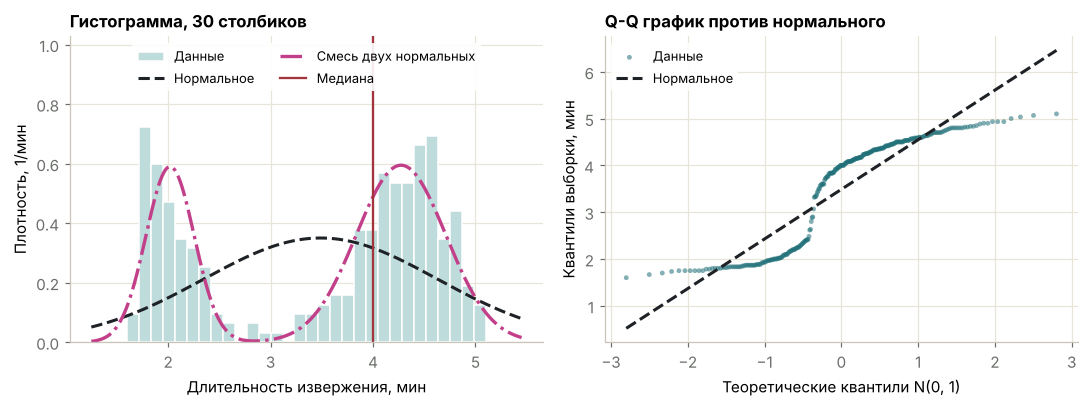

Шапиро-Уилк: W = 0.8459, p = 9.04e-16


In [6]:
gey_plot_eda(df, "duration", bins=30, mixture=True)
plt.show()

w, p = stats.shapiro(x)
print(f"Шапиро-Уилк: W = {w:.4f}, p = {p:.2e}")

**Выводы.** Распределение **двугорбое**: пик около 2 мин и пик около 4.3 мин. Шапиро-Уилк: W = 0.846,
p ≈ 9·10⁻¹⁶ — нормальность отвергаем. Q-Q график идёт ступенькой, а не вдоль прямой.

#### Подбор распределения: нормальное и смесь двух нормальных

Если извержения бывают двух типов, естественно описать $X$ смесью двух нормальных распределений:

$$f(x)=w\,\frac{1}{\sigma_1}\varphi\!\left(\frac{x-\mu_1}{\sigma_1}\right)+(1-w)\,\frac{1}{\sigma_2}\varphi\!\left(\frac{x-\mu_2}{\sigma_2}\right),\qquad \varphi(t)=\frac{1}{\sqrt{2\pi}}e^{-t^2/2}.$$

Здесь $w$ — доля коротких извержений, $\mu_1,\sigma_1$ и $\mu_2,\sigma_2$ — центр и разброс каждого режима.
Пять параметров $(w,\mu_1,\sigma_1,\mu_2,\sigma_2)$ оцениваем методом максимального правдоподобия через
ЕМ-алгоритм (Dempster, Laird, Rubin, 1977): на E-шаге для каждого наблюдения считаем вероятность
принадлежности к каждому режиму, на М-шаге пересчитываем параметры как взвешенные среднее и std.
Модели сравниваем по $AIC=2k-2\ln L$ (меньше — лучше) и расстоянию Колмогорова-Смирнова $D$.

In [7]:
fit_x, mix_x = gey_fit_table(x)
fit_x

,k,AIC,KS D,Параметры
Модель,,,,
Нормальное,2,846.8341,0.1816,"μ = 3.488, σ = 1.139"
Смесь двух нормальных,5,562.7201,0.0486,w = 0.35 / 0.65; μ = 2.02 / 4.27; σ = 0.24 / 0.44


**Выводы.** Смесь двух нормальных описывает $X$ намного лучше одной нормальной: AIC 562.7 против 846.8,
$D$ = 0.049 против 0.182. Оценки: $w \approx 0.35$, $\mu_1 \approx 2.02$, $\mu_2 \approx 4.27$ мин —
примерно каждое третье извержение короткое. p-value критерия KS не используем: параметры подобраны по тем же
данным, поэтому сравниваем только $D$ и AIC.

<a id="rv2"></a>
## Random Variable 02 (время ожидания следующего извержения Y)
### Description

**Величина $Y$ — время ожидания следующего извержения, мин.**

| Параметр | Значение |
|---|---|
| Единицы измерения | мин |
| Тип | непрерывная, записана целыми минутами |
| Диапазон в данных | 43–96 мин |

**Почему это случайная величина.** Пауза зависит от того, как быстро подземный канал снова наполнится
водой и прогреется. Эти процессы скрыты под землёй и не наблюдаются. Длительность прошедшего извержения
подсказывает ожидание, но не определяет его: даже у извержений почти одинаковой длины паузы заметно
различаются (пример — в ячейке ниже). Значит, $Y$ нельзя вычислить по формуле, и до наблюдения её значение
неизвестно. Формально: для того же случайного выбора извержения $\omega$ значение $Y(\omega)$ — пауза до
следующего извержения.

In [8]:
band = df[(df["duration"] >= 4.3) & (df["duration"] <= 4.7)]["waiting"]
print(f"Извержений длительностью 4.3–4.7 мин: {len(band)}")
print(f"Ожидание следующего: от {band.min()} до {band.max()} мин, std = {band.std():.1f} мин")

Извержений длительностью 4.3–4.7 мин: 69
Ожидание следующего: от 72 до 93 мин, std = 5.1 мин


### EDA & Distribution
#### Описательные статистики и выбросы

In [9]:
y = df["waiting"]
pd.Series(gey_describe(y)).map(lambda v: f"{v:.4f}" if abs(v) >= 1e-3 or v == 0 else f"{v:.2e}").to_frame("waiting, мин")

,"waiting, мин"
n,272.0000
Среднее,70.8971
Медиана,76.0000
Std,13.5950
Min,43.0000
Q1,58.0000
Q3,82.0000
Max,96.0000
Асимметрия,-0.4186
Эксцесс,-1.1415


**Выводы.** Среднее 70.9 мин меньше медианы 76 мин, эксцесс −1.14 — снова признак двух горбов.
Выбросов по правилу 1.5·IQR нет.

#### Форма распределения и подбор модели

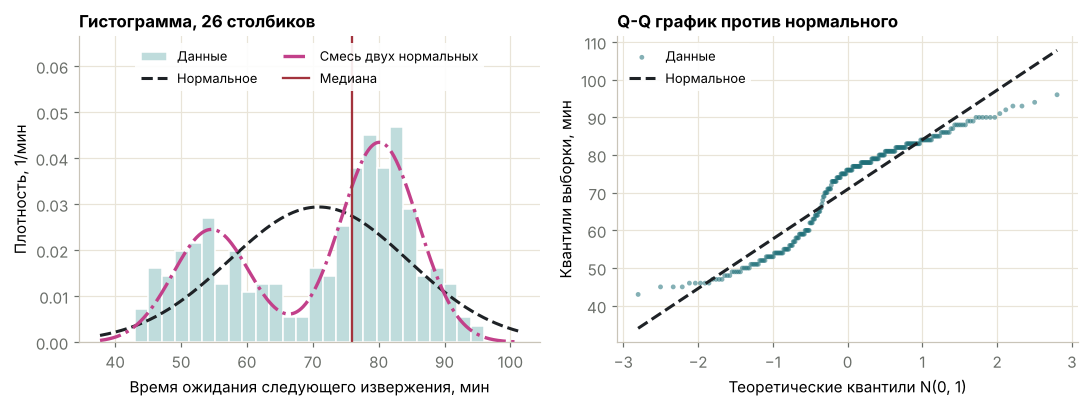

Шапиро-Уилк: W = 0.9221, p = 1.02e-10


,k,AIC,KS D,Параметры
Модель,,,,
Нормальное,2,2194.5776,0.1556,"μ = 70.897, σ = 13.570"
Смесь двух нормальных,5,2078.0035,0.0335,w = 0.36 / 0.64; μ = 54.61 / 80.09; σ = 5.87 / 5.87


In [10]:
gey_plot_eda(df, "waiting", bins=26, mixture=True)
plt.show()

w, p = stats.shapiro(y)
print(f"Шапиро-Уилк: W = {w:.4f}, p = {p:.2e}")
fit_y, mix_y = gey_fit_table(y)
fit_y

**Выводы.** $Y$ тоже двугорбое: пики около 55 и 80 мин. Шапиро-Уилк: W = 0.922, p ≈ 1·10⁻¹⁰ — нормальность
отвергаем. Смесь двух нормальных снова лучше одной нормальной: AIC 2078.0 против 2194.6, $D$ = 0.034 против 0.156.

<a id="indep"></a>
## Независимость X и Y

$X$ и $Y$ описывают одно и то же извержение — это величины одной природы события, поэтому проверяем их зависимость:
коэффициенты Пирсона $r$ и Спирмена $\rho$, критерий $\chi^2$ по таблице квартилей и V Крамера
$V=\sqrt{\chi^2/(n\,(\min(k,l)-1))}$.

$H_0$: $X$ и $Y$ независимы; $H_1$: зависимы; $\alpha = 0.05$.

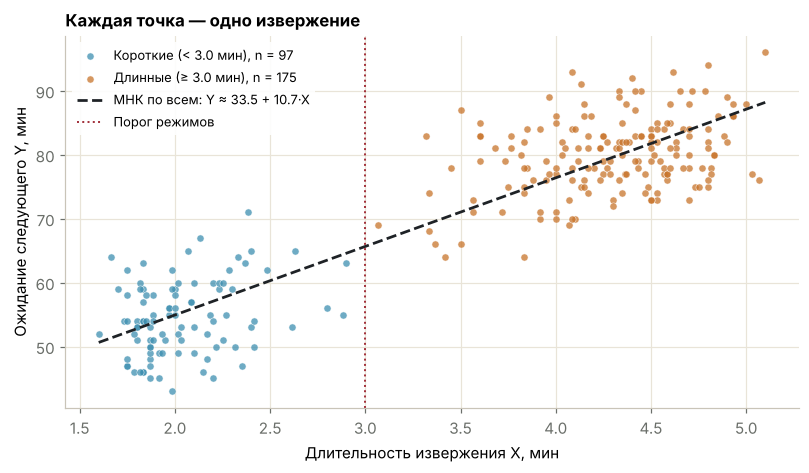

Пирсон r = 0.901 (p = 8.1e-100)
Спирмен rho = 0.778 (p = 2.0e-56)
chi2 = 186.8, df = 9, p = 2.0e-35
V Крамера = 0.478, мин. ожидаемая частота = 13.9


,43–58 мин,58–76 мин,76–82 мин,82–96 мин
длительность \ ожидание,,,,
1.60–2.16 мин,54,14,0,0
2.16–4.00 мин,16,32,13,11
4.00–4.45 мин,0,14,29,21
4.45–5.10 мин,0,13,28,27


In [11]:
gey_plot_scatter(df, threshold=3.0)
plt.show()

dep = gey_dependence(df)
print(f"Пирсон r = {dep['r']:.3f} (p = {dep['pr']:.1e})")
print(f"Спирмен rho = {dep['rho']:.3f} (p = {dep['ps']:.1e})")
print(f"chi2 = {dep['chi2']:.1f}, df = {dep['dof']}, p = {dep['pc']:.1e}")
print(f"V Крамера = {dep['v']:.3f}, мин. ожидаемая частота = {dep['min_expected']:.1f}")
dep["table"]

In [12]:
# Связь внутри режимов (порог 3 мин по длительности)
gey_regimes(df, threshold=3.0)

,n,"Среднее X, мин","Среднее Y, мин",Пирсон r,Спирмен ρ
Режим,,,,,
Короткие,97,2.0381,54.4948,0.2902,0.250
Длинные,175,4.2913,79.9886,0.3728,0.295
Все,272,3.4878,70.8971,0.9008,0.778


**Выводы.** $X$ и $Y$ **зависимы, связь сильная**: $r = 0.901$, $\rho = 0.778$, оба p-value практически нулевые.
$\chi^2 = 186.8$ при 9 степенях свободы, V Крамера 0.48; минимальная ожидаемая частота 13.9 больше 5, поэтому
критерий применим. $H_0$ о независимости отвергаем.

**Откуда связь.** Длинное извержение выбрасывает больше воды и тепла, и системе нужно больше времени, чтобы снова
накопить их. По прямой МНК $Y \approx 33.5 + 10.7\,X$: каждая минута извержения добавляет около 11 мин ожидания.

**Внутри режимов связь слабее:** у коротких извержений $r = 0.29$, у длинных $r = 0.37$. Большую часть общей
корреляции создаёт то, что режимов два. Поэтому Спирмен ниже Пирсона: ранги внутри облаков перемешаны.

Генерировать $X$ и $Y$ по отдельности как независимые нельзя: пару нужно моделировать совместно.

<a id="limits"></a>
## Ограничения: извержения идут подряд

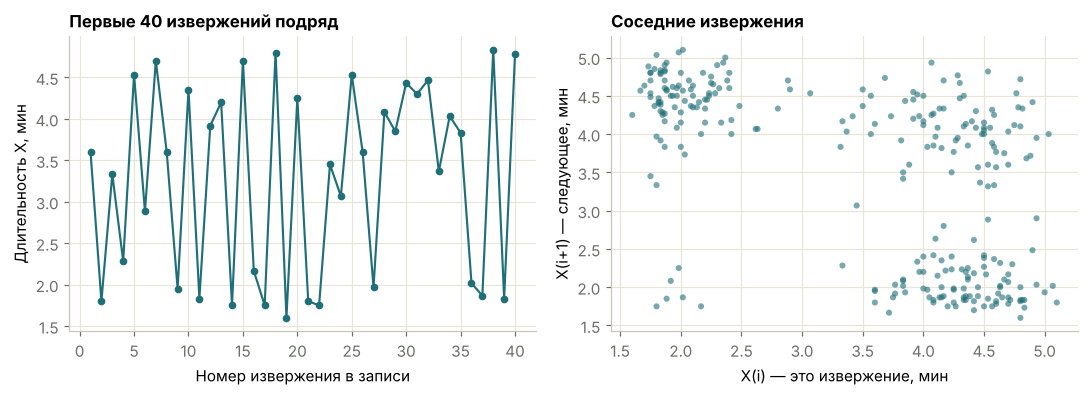

,корреляция
"X(i), X(i+1)",-0.5499
"Y(i), Y(i+1)",-0.5398
"X(i), Y(i)",0.9008
"X(i), Y(i+1)",-0.4820


In [13]:
gey_plot_lag(df)
plt.show()
pd.Series(gey_lag(df)).to_frame("корреляция")

**Выводы.** Соседние извержения связаны: корреляция $X_i$ и $X_{i+1}$ равна −0.55, короткое и длинное
извержения часто чередуются. Значит, наблюдения не вполне независимы, и p-value выше приблизительные:
все использованные критерии предполагают независимые наблюдения. Главный вывод от этого не меняется —
корреляция $X$ и $Y$ одного извержения (0.90) слишком далека от нуля. Длительность связана с паузой после
извержения (0.90) и обратно — с паузой после следующего (−0.48), что согласуется с описанием набора:
$Y$ — ожидание после извержения $X$.

<a id="resume"></a>
## Lab resume

**Данные.** 272 последовательных извержения гейзера Old Faithful — датасет, не связанный с вином.
Исследованы две величины одного события: длительность извержения $X$ и время ожидания следующего $Y$, обе в минутах.

**Случайность.** Обе величины определяются скрытыми подземными процессами (накопление воды и тепла),
их нельзя вычислить по формуле до наблюдения, а запись содержит погрешность и округление.

**Распределения.** Обе величины двугорбые и не нормальные. Смесь двух нормальных описывает их намного лучше
одной нормальной. Для $X$ режимы — около 2.0 и 4.3 мин, доля коротких около 35%. Выбросов по IQR нет.

**Зависимость.** $X$ и $Y$ сильно зависимы ($r = 0.90$, $\rho = 0.78$, V Крамера 0.48, $\chi^2$ отвергает
независимость). Основной вклад дают два режима извержений; внутри режима связь слабая, но положительная.

**Ограничения.** Наблюдения идут подряд и зависят друг от друга, поэтому p-value приблизительные.

**Для генератора (спринт 2).** Пару $(X, Y)$ нельзя генерировать независимо. Естественная схема — метод
суперпозиции: сначала разыграть режим с вероятностью $w$, затем значения внутри режима.

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|---|---|---|---|
| Доп. КТиД: отдельный датасет | [Общее описание данных](#data) | 1 | извержения гейзера Old Faithful, 272 строки; с Wine Quality не связан |
| Две случайные величины | [RV 01](#rv1) · [RV 02](#rv2) | 1 | длительность извержения X, мин; ожидание следующего извержения Y, мин |
| Доказательство случайности | [RV 01](#rv1) · [RV 02](#rv2) → Description | 1 | случайный выбор извержения, скрытые подземные процессы, погрешность записи; разброс Y при одинаковом X |
| Зависимость величин одной природы события | [Независимость X и Y](#indep) | 1 | Пирсон, Спирмен, χ² и V Крамера, связь внутри режимов |
| EDA | [RV 01](#rv1) · [RV 02](#rv2) → EDA & Distribution | 1 | статистики, выбросы IQR, гистограммы, Q-Q, Шапиро-Уилк |
| Подбор распределения | [RV 01](#rv1) · [RV 02](#rv2) | — | сверх задания: смесь двух нормальных (ЕМ) против нормального, AIC и KS D |
| Проверка допущений | [Ограничения](#limits) | — | сверх задания: зависимость соседних извержений |

<a id="refs"></a>
## Литература

1. Azzalini A., Bowman A. W. A look at some data on the Old Faithful geyser // Applied Statistics. 1990. Vol. 39, № 3. P. 357–365.
2. Härdle W. Smoothing Techniques: With Implementation in S. New York: Springer, 1991.
3. R Core Team. Набор данных `faithful` (пакет datasets): https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/faithful.html
4. Waskom M. seaborn-data, файл `geyser.csv`: https://github.com/mwaskom/seaborn-data
5. Dempster A. P., Laird N. M., Rubin D. B. Maximum likelihood from incomplete data via the EM algorithm // Journal of the Royal Statistical Society. Series B. 1977. Vol. 39, № 1. P. 1–38.
6. Гмурман В. Е. Теория вероятностей и математическая статистика.
7. Документация SciPy: `scipy.stats.pearsonr`, `spearmanr`, `chi2_contingency`, `shapiro`.